# 04 — Modelling

**Input**  : `data/processed/X_train.npy`, `y_train.npy`, `X_test.npy`, `y_test.npy`  
**Output** : `models/best_model.pkl` + runs MLflow (`http://localhost:5000`)

Pipeline :
1. Chargement des données (train / test)
2. Baseline — entraînement des 4 modèles, évaluation sur X_test
3. Sélection du meilleur modèle baseline
4. Hyperparameter tuning (GridSearchCV avec CV sur X_train uniquement)
5. Évaluation finale sur X_test
6. Sauvegarde du meilleur modèle

In [17]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from dotenv import load_dotenv

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, classification_report,
    RocCurveDisplay
)

import mlflow
from mlflow.tracking import MlflowClient
import mlflow.sklearn
import mlflow.xgboost

# Charger le .env (MLFLOW_TRACKING_URI)
load_dotenv(Path('../.env'))

PROCESSED_DIR = Path('../data/processed')
MODELS_DIR    = Path('../models')
FIGURES_DIR   = Path('../reports/figures')

MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE   = 42
CV_FOLDS       = 3
EXPERIMENT_NAME = 'drug-toxicity-classification'

TRACKING_URI = os.getenv('MLFLOW_TRACKING_URI', 'http://localhost:5000')
print(f'MLflow tracking URI : {TRACKING_URI}')

MLflow tracking URI : http://localhost:5000


## 1. Chargement des données

In [ ]:
X_train = np.load(PROCESSED_DIR / 'X_train.npy')
y_train = np.load(PROCESSED_DIR / 'y_train.npy')
X_test  = np.load(PROCESSED_DIR / 'X_test.npy')
y_test  = np.load(PROCESSED_DIR / 'y_test.npy')

print(f'Train : {X_train.shape} | positifs : {y_train.sum()} ({y_train.mean():.1%})')
print(f'Test  : {X_test.shape}  | positifs : {y_test.sum()} ({y_test.mean():.1%})')

## 2. Configuration MLflow

In [54]:
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

print(f'Expérience : {EXPERIMENT_NAME}')
print(f'Tracking   : {mlflow.get_tracking_uri()}')

Expérience : drug-toxicity-classification
Tracking   : http://localhost:5000


## 3. Définition des modèles baseline

In [55]:
MODELS = {
    'RandomForest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=3,
        max_features='sqrt',
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        verbosity=0,
    ),
    'SVM': SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        class_weight='balanced',
        random_state=RANDOM_STATE,
    ),
    'LogisticRegression': LogisticRegression(
        C=1.0,
        max_iter=1000,
        class_weight='balanced',
        solver='lbfgs',
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

print(f'{len(MODELS)} modèles à entraîner : {list(MODELS.keys())}')

4 modèles à entraîner : ['RandomForest', 'XGBoost', 'SVM', 'LogisticRegression']


## 4. Entraînement baseline + MLflow tracking

In [ ]:
def compute_metrics(y_true, y_pred, y_prob):
    return {
        'roc_auc':   roc_auc_score(y_true, y_prob),
        'accuracy':  accuracy_score(y_true, y_pred),
        'f1':        f1_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall':    recall_score(y_true, y_pred),
    }

baseline_results = {}

for name, model in MODELS.items():
    print(f'\n--- {name} ---')

    with mlflow.start_run(run_name=f'baseline_{name}'):

        mlflow.set_tag('version', 'v2')

        model.fit(X_train, y_train)

        y_pred_test = model.predict(X_test)
        y_prob_test = model.predict_proba(X_test)[:, 1]
        test_metrics = compute_metrics(y_test, y_pred_test, y_prob_test)

        mlflow.log_params(model.get_params())
        mlflow.log_param('model_type', name)
        mlflow.log_param('train_size', len(X_train))
        mlflow.log_param('test_size',  len(X_test))
        mlflow.log_param('n_features', X_train.shape[1])
        mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})

        if name == 'XGBoost':
            mlflow.xgboost.log_model(model, 'model')
        else:
            mlflow.sklearn.log_model(model, 'model')

        run_id = mlflow.active_run().info.run_id

    baseline_results[name] = {'model': model, 'metrics': test_metrics, 'run_id': run_id}

    print(f'  ROC-AUC : {test_metrics["roc_auc"]:.4f}')
    print(f'  F1      : {test_metrics["f1"]:.4f}')
    print(f'  Recall  : {test_metrics["recall"]:.4f}')

## 5. Comparaison des modèles baseline

In [ ]:
df_results = pd.DataFrame(
    {name: res['metrics'] for name, res in baseline_results.items()}
).T.sort_values('roc_auc', ascending=False)

print('=== Résultats baseline (test set) ===')
print(df_results.round(4).to_string())

best_baseline_name = df_results.index[0]
print(f'\nMeilleur modèle baseline : {best_baseline_name} (ROC-AUC = {df_results.loc[best_baseline_name, "roc_auc"]:.4f})')

In [ ]:
metrics_to_plot = ['roc_auc', 'f1', 'precision', 'recall', 'accuracy']
x = np.arange(len(metrics_to_plot))
width = 0.2
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

fig, ax = plt.subplots(figsize=(12, 5))
for i, (name, res) in enumerate(baseline_results.items()):
    vals = [res['metrics'][m] for m in metrics_to_plot]
    ax.bar(x + i * width, vals, width, label=name, color=colors[i], alpha=0.85)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Comparaison des modèles baseline (test set)')
ax.legend()
ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'baseline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Hyperparameter Tuning (GridSearchCV) — meilleur baseline

In [ ]:
PARAM_GRIDS = {
    'RandomForest': {
        'n_estimators':     [100, 200],
        'max_depth':        [5, 10, 15, 20],
        'min_samples_leaf': [2, 5, 10],
        'max_features':     ['sqrt', 'log2'],
    },
    'XGBoost': {
        'n_estimators':  [100, 200],
        'max_depth':     [4, 6],
        'learning_rate': [0.05, 0.1],
        'subsample':     [0.8, 1.0],
        'reg_alpha':     [0, 0.1],
    },
    'SVM': {
        'C':      [0.1, 1, 10],
        'gamma':  ['scale', 'auto'],
        'kernel': ['rbf'],
    },
    'LogisticRegression': {
        'C':       [0.01, 0.1, 1, 10],
        'penalty': ['l2'],
    },
}

tuning_name  = best_baseline_name
tuning_model = MODELS[tuning_name]
tuning_grid  = PARAM_GRIDS[tuning_name]

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print(f'GridSearchCV sur : {tuning_name}')
print(f'Grid             : {tuning_grid}')
print(f'CV               : {CV_FOLDS} folds stratifiés — fitté sur X_train uniquement')

grid_search = GridSearchCV(
    estimator=tuning_model,
    param_grid=tuning_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
)

grid_search.fit(X_train, y_train)

best_model  = grid_search.best_estimator_  # refitté sur tout X_train avec les meilleurs params
best_params = grid_search.best_params_
best_cv_auc = grid_search.best_score_

print(f'\nMeilleurs hyperparamètres : {best_params}')
print(f'ROC-AUC CV ({CV_FOLDS}-fold, X_train) : {best_cv_auc:.4f}')

## 7. Log MLflow — modèle tuné + évaluation finale

In [ ]:
with mlflow.start_run(run_name=f'tuned_{tuning_name}'):

    mlflow.set_tag('version', 'v2')

    y_pred_test_tuned = best_model.predict(X_test)
    y_prob_test_tuned = best_model.predict_proba(X_test)[:, 1]
    test_metrics_tuned = compute_metrics(y_test, y_pred_test_tuned, y_prob_test_tuned)

    mlflow.log_param('model_type',    tuning_name)
    mlflow.log_param('tuning_method', 'GridSearchCV')
    mlflow.log_param('cv_folds',      CV_FOLDS)
    mlflow.log_param('train_size',    len(X_train))
    mlflow.log_param('test_size',     len(X_test))
    mlflow.log_param('n_features',    X_train.shape[1])
    mlflow.log_params(best_params)

    mlflow.log_metric('cv_roc_auc', best_cv_auc)
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics_tuned.items()})

    if tuning_name == 'XGBoost':
        mlflow.xgboost.log_model(best_model, 'best_model')
    else:
        mlflow.sklearn.log_model(best_model, 'best_model')

    best_run_id = mlflow.active_run().info.run_id

print('=== Métriques finales (test set) ===')
print(f'ROC-AUC CV  ({CV_FOLDS}-fold, X_train) : {best_cv_auc:.4f}   ← sélection des hyperparams')
print(f'ROC-AUC test                           : {test_metrics_tuned["roc_auc"]:.4f}   ← évaluation finale')
print()
for k, v in test_metrics_tuned.items():
    print(f'  {k:12s} : {v:.4f}')

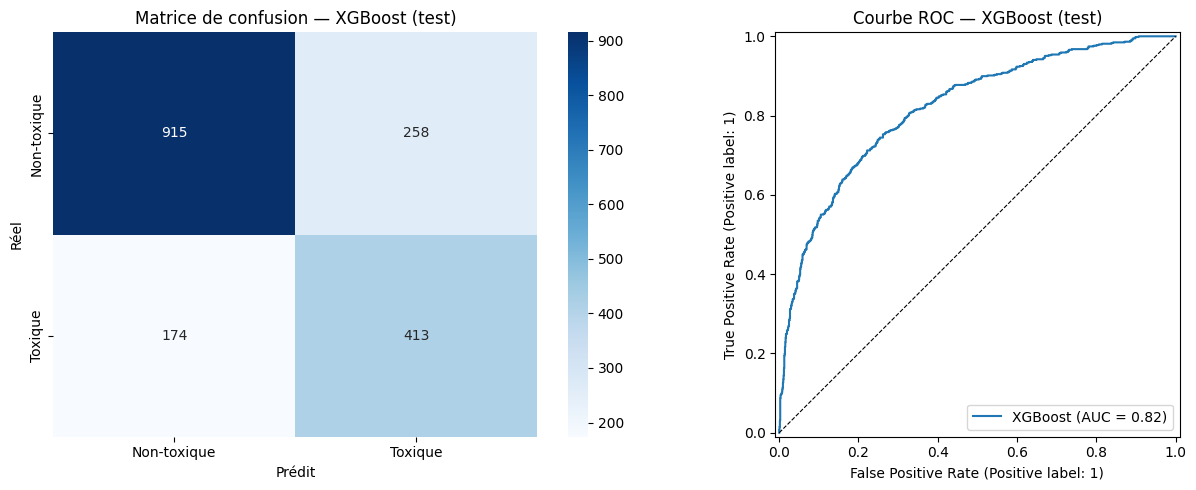


=== Classification Report ===
              precision    recall  f1-score   support

 Non-toxique       0.84      0.78      0.81      1173
     Toxique       0.62      0.70      0.66       587

    accuracy                           0.75      1760
   macro avg       0.73      0.74      0.73      1760
weighted avg       0.77      0.75      0.76      1760



In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_test_tuned)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Non-toxique', 'Toxique'],
    yticklabels=['Non-toxique', 'Toxique']
)
axes[0].set_xlabel('Prédit')
axes[0].set_ylabel('Réel')
axes[0].set_title(f'Matrice de confusion — {tuning_name} (test)')

RocCurveDisplay.from_predictions(y_test, y_prob_test_tuned, ax=axes[1], name=tuning_name)
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=0.8)
axes[1].set_title(f'Courbe ROC — {tuning_name} (test)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / f'best_model_evaluation_{tuning_name}.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== Classification Report ===')
print(classification_report(y_test, y_pred_test_tuned, target_names=['Non-toxique', 'Toxique']))

In [16]:
baseline_test_auc = baseline_results[tuning_name]['metrics']['roc_auc']
tuned_test_auc    = test_metrics_tuned['roc_auc']

print(f'ROC-AUC test — baseline : {baseline_test_auc:.4f}')
print(f'ROC-AUC test — tuned    : {tuned_test_auc:.4f}  (gain : {tuned_test_auc - baseline_test_auc:+.4f})')
print(f'ROC-AUC CV   — tuned    : {best_cv_auc:.4f}  ({CV_FOLDS}-fold sur X_train)')

ROC-AUC test — baseline : 0.8132
ROC-AUC test — tuned    : 0.8191  (gain : +0.0060)
ROC-AUC CV   — tuned    : 0.7918  (3-fold sur X_train)


## 8. Sauvegarde du meilleur modèle

In [14]:
model_path = MODELS_DIR / 'best_model.pkl'
joblib.dump(best_model, model_path)

meta = {
    'model_type':        tuning_name,
    'best_params':       best_params,
    'cv_roc_auc':        round(best_cv_auc, 4),
    'test_roc_auc':      round(test_metrics_tuned['roc_auc'], 4),
    'test_f1':           round(test_metrics_tuned['f1'], 4),
    'test_recall':       round(test_metrics_tuned['recall'], 4),
    'test_precision':    round(test_metrics_tuned['precision'], 4),
    'mlflow_run_id':     best_run_id,
    'mlflow_experiment': EXPERIMENT_NAME,
}
pd.Series(meta).to_json(MODELS_DIR / 'best_model_meta.json', indent=2)

print(f'Modèle sauvegardé : {model_path}')
print(f'Taille            : {model_path.stat().st_size / 1024:.1f} KB')
print(f'\nMétadonnées :')
for k, v in meta.items():
    print(f'  {k:22s} : {v}')

Modèle sauvegardé : ..\models\best_model.pkl
Taille            : 525.7 KB

Métadonnées :
  model_type             : XGBoost
  best_params            : {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 200, 'reg_alpha': 0.1, 'subsample': 0.8}
  cv_roc_auc             : 0.7918
  test_roc_auc           : 0.8191
  test_f1                : 0.6566
  test_recall            : 0.7036
  test_precision         : 0.6155
  mlflow_run_id          : 07b4901960394261b9ddb2b9dd39b5c8
  mlflow_experiment      : drug-toxicity-classification


### 9.register le best modèle et passage en production

In [ ]:
with mlflow.start_run(run_id="07b4901960394261b9ddb2b9dd39b5c8"):
    mlflow.xgboost.log_model(
        xgb_model=best_model,
        artifact_path="model"
    )

2026/05/31 20:46:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/31 20:46:50 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run tuned_XGBoost at: http://localhost:5000/#/experiments/1/runs/07b4901960394261b9ddb2b9dd39b5c8
🧪 View experiment at: http://localhost:5000/#/experiments/1


KeyboardInterrupt: 

In [19]:
run_id = "07b4901960394261b9ddb2b9dd39b5c8"  # ton run id

model_uri = f"runs:/{run_id}/model"

mlflow.register_model(
    model_uri=model_uri,
    name="drug-toxicity-xgboost"
)

Registered model 'drug-toxicity-xgboost' already exists. Creating a new version of this model...


MlflowException: Unable to find a logged_model with artifact_path model under run 07b4901960394261b9ddb2b9dd39b5c8

In [ ]:
client = MlflowClient()

# Changer le stage → Production
client.transition_model_version_stage(
    name="drug-toxicity-xgboost",
    version=1,
    stage="Production"
)